In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
sales2023=pd.read_clipboard()

In [6]:
sales2023.tail(2)

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice
58,O202300058,31-12-2023,C1108,P2019,9,26.0
59,O202300059,31-12-2023,C1130,P2010,3,91.0


In [7]:
sales2024=pd.read_clipboard()

In [8]:
sales2024.tail(2)

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice
58,O202400058,31-12-2024,C1178,P2021,1,78.0
59,O202400059,31-12-2024,C1200,P2023,2,545.0


In [9]:
customers=pd.read_clipboard()

In [22]:
product = pd.read_json(r"C:\Users\RAJA PC\Desktop\products_clean.json")

In [17]:
customers.head(5)

,CustomerID,CustomerName,Region,Segment
0,C1000,Alice,North,Consumer
1,C1001,Bob,South,Corporate
2,C1002,Carol,East,Home Office
3,C1003,Dave,West,Consumer
4,C1004,Eve,Central,Corporate


In [24]:
product.head(5)

,products
0,"{'ProductID': 'P2000', 'ProductName': 'Laptop'..."
1,"{'ProductID': 'P2001', 'ProductName': 'Smartph..."
2,"{'ProductID': 'P2002', 'ProductName': 'Tablet'..."
3,"{'ProductID': 'P2003', 'ProductName': 'Headpho..."
4,"{'ProductID': 'P2004', 'ProductName': 'Monitor..."


In [27]:
combined_sales=pd.concat([sales2023,sales2024])

In [28]:
combined_sales.shape

(120, 6)

In [29]:
final_data=pd.merge(combined_sales,customers)

In [30]:
final_data.head(5)

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice,CustomerName,Region,Segment
0,O202300000,15-01-2023,C1000,P2003,3,245.50,Alice,North,Consumer
1,O202300001,18-01-2023,C1012,P2007,5,1899.00,Mia,East,Corporate
2,O202300002,03-02-2023,C1044,P2012,2,320.75,Nisha,Central,Consumer
3,O202300004,11-03-2023,C1005,P2022,1,780.00,Frank,North,Consumer
4,O202300009,25-12-2023,C1021,P2010,3,89.95,Victor,South,Corporate


In [33]:
final_data.duplicated().sum()

np.int64(0)

In [34]:
final_data.isnull().sum()

OrderID         0
OrderDate       0
CustomerID      0
ProductID       0
Quantity        0
UnitPrice       0
CustomerName    0
Region          0
Segment         0
dtype: int64

In [35]:
final_data.dtypes

OrderID          object
OrderDate        object
CustomerID       object
ProductID        object
Quantity          int64
UnitPrice       float64
CustomerName     object
Region           object
Segment          object
dtype: object

In [36]:
final_data['OrderDate']=pd.to_datetime(final_data['OrderDate'])

C:\Users\RAJA PC\AppData\Local\Temp\ipykernel_18004\4217896546.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  final_data['OrderDate']=pd.to_datetime(final_data['OrderDate'])


In [37]:
final_data.dtypes

OrderID                 object
OrderDate       datetime64[ns]
CustomerID              object
ProductID               object
Quantity                 int64
UnitPrice              float64
CustomerName            object
Region                  object
Segment                 object
dtype: object

In [38]:
final_data_copy=final_data.copy()

In [39]:
final_data_copy['Revenue']=final_data_copy['Quantity']*final_data_copy['UnitPrice']
final_data_copy.head()

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice,CustomerName,Region,Segment,Revenue
0,O202300000,2023-01-15,C1000,P2003,3,245.50,Alice,North,Consumer,736.50
1,O202300001,2023-01-18,C1012,P2007,5,1899.00,Mia,East,Corporate,9495.00
2,O202300002,2023-02-03,C1044,P2012,2,320.75,Nisha,Central,Consumer,641.50
3,O202300004,2023-03-11,C1005,P2022,1,780.00,Frank,North,Consumer,780.00
4,O202300009,2023-12-25,C1021,P2010,3,89.95,Victor,South,Corporate,269.85


In [40]:
final_data_copy['Year']=final_data_copy['OrderDate'].dt.year

In [41]:
final_data_copy['Month']=final_data_copy['OrderDate'].dt.month
final_data_copy['Day']=final_data_copy['OrderDate'].dt.day

In [42]:
final_data_copy.head(5)

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice,CustomerName,Region,Segment,Revenue,Year,Month,Day
0,O202300000,2023-01-15,C1000,P2003,3,245.50,Alice,North,Consumer,736.50,2023,1,15
1,O202300001,2023-01-18,C1012,P2007,5,1899.00,Mia,East,Corporate,9495.00,2023,1,18
2,O202300002,2023-02-03,C1044,P2012,2,320.75,Nisha,Central,Consumer,641.50,2023,2,3
3,O202300004,2023-03-11,C1005,P2022,1,780.00,Frank,North,Consumer,780.00,2023,3,11
4,O202300009,2023-12-25,C1021,P2010,3,89.95,Victor,South,Corporate,269.85,2023,12,25


In [43]:
final_data_copy['Quantity'].describe().round(2)

count    33.00
mean      3.85
std       2.09
min       1.00
25%       2.00
50%       4.00
75%       5.00
max       8.00
Name: Quantity, dtype: float64

In [44]:
final_data_copy['Revenue'].describe().round(2)

count      33.00
mean     1177.57
std      1723.28
min        72.00
25%       250.00
50%       560.00
75%      1620.00
max      9495.00
Name: Revenue, dtype: float64

In [48]:
final_data_copy['Quantity'].corr(final_data_copy['Revenue'])

np.float64(0.1553038876328967)

In [52]:
final_data_copy[['UnitPrice','Revenue']].corr()

,UnitPrice,Revenue
UnitPrice,1.000000,0.827229
Revenue,0.827229,1.000000


In [57]:
final_data_copy.groupby(by=["Year","Month","Day"])['Revenue'].mean().round().sort_values(ascending=False)

Year  Month  Day
2023  1      18     9495.0
2024  4      30     2875.0
2023  7      15     2726.0
2024  12     24     2600.0
      11     4      2370.0
2023  9      26     2160.0
2024  12     28     1700.0
2023  1      9      1700.0
      12     29     1620.0
2024  10     28     1550.0
2023  7      7      1520.0
      1      5      1040.0
      12     28      795.0
      3      11      780.0
      1      15      736.0
      2      3       642.0
2024  8      27      560.0
      12     29      460.0
      2      19      444.0
2023  9      17      420.0
2024  2      27      288.0
             14      276.0
2023  12     25      270.0
      4      14      252.0
2024  11     12      250.0
2023  11     21      225.0
2024  5      30      224.0
             22      212.0
      8      9       184.0
             18      150.0
2023  4      25      137.0
2024  9      28      126.0
2023  11     29       72.0
Name: Revenue, dtype: float64

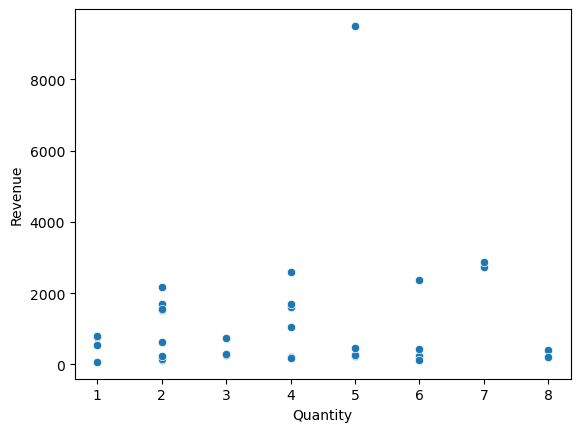

In [65]:

sns.scatterplot(data=final_data_copy,x='Quantity',y='Revenue')
plt.show()

<Axes: xlabel='UnitPrice', ylabel='Revenue'>

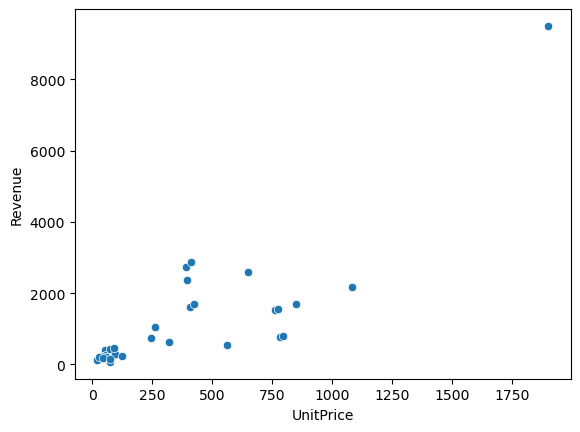

In [66]:
sns.scatterplot(x='UnitPrice',y='Revenue',data=final_data_copy)

<Axes: xlabel='Month', ylabel='Revenue'>

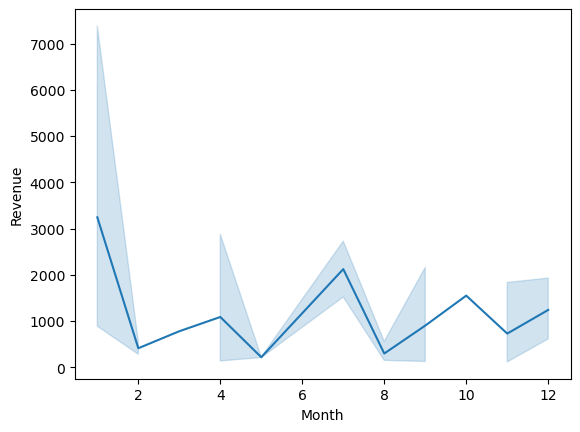

In [67]:
sns.lineplot(x='Month',y='Revenue',data=final_data_copy)

<Axes: xlabel='Year', ylabel='Revenue'>

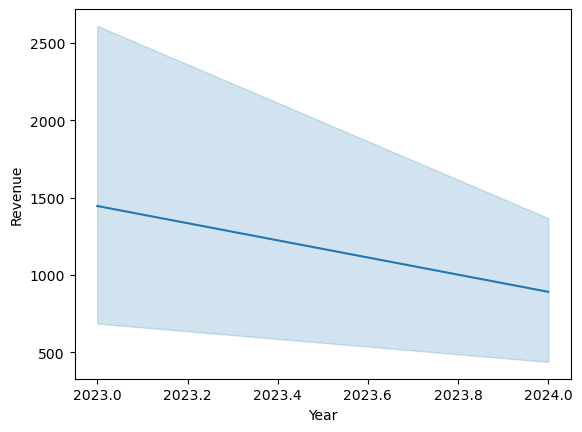

In [68]:
sns.lineplot(x='Year',y='Revenue',data=final_data_copy)

<Axes: xlabel='Region', ylabel='Revenue'>

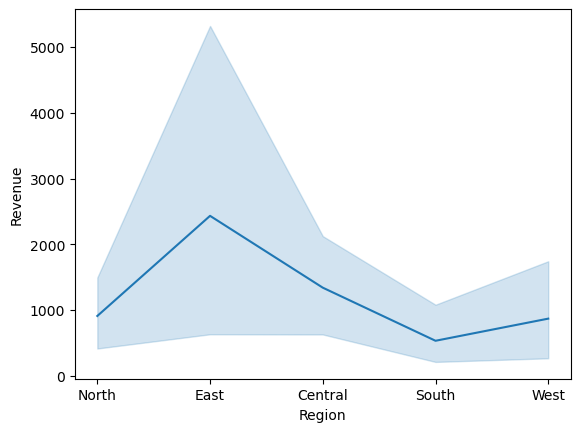

In [69]:
sns.lineplot(x='Region',y='Revenue',data=final_data_copy)